# Datathon Task 2 V1 - EDA, OCR Hyperlink Graph, dan Candidate Ranking

## Tim RIZZZ - Universitas Airlangga

Notebook V1 end-to-end untuk memprediksi next click pada navigasi Wikipedia. Pipeline memperlakukan screenshot sebagai sumber hyperlink, bukan sebagai gambar klasifikasi biasa.

Tahapan utama: audit data, EDA, deteksi link biru, OCR dan title matching, pembentukan directed graph, grouped validation berdasarkan target, perbandingan beberapa baseline/model, final refit, dan pembuatan submission.

**Metric utama:** exact-match accuracy. **Prinsip validation:** seluruh state untuk target yang sama harus berada pada fold yang sama.


## 0. Setup, konfigurasi, dan reproducibility

Seluruh path, seed, batas candidate, dan mode eksekusi ditetapkan di satu tempat. Set `DATATON_FAST_MODE=1` hanya untuk smoke test; run submission sebaiknya memakai mode penuh.


In [1]:
from __future__ import annotations

import gc, importlib.util, io, json, math, os, random, re, shutil, subprocess, tempfile, time, unicodedata, warnings
from collections import Counter, defaultdict, deque
from difflib import SequenceMatcher
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold

try:
    from IPython.display import display
except Exception:
    def display(obj): print(obj.to_string() if hasattr(obj, 'to_string') else obj)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')

SEED = 42
random.seed(SEED); np.random.seed(SEED)
FAST_MODE = os.getenv('DATATON_FAST_MODE', '0') == '1'
N_SPLITS = 3
MAX_TRAIN_CANDIDATES = 40 if not FAST_MODE else 20
MAX_EVAL_CANDIDATES = 80 if not FAST_MODE else 30
OCR_PAGE_LIMIT = int(os.getenv('DATATON_OCR_PAGE_LIMIT', '0'))
OCR_CHECKPOINT_EVERY = 100

KAGGLE_DATASET_PATH = Path('/kaggle/input/competitions/datathon-task-2/dataset-task2')
SEARCH_ROOTS = [Path.cwd(), *Path.cwd().parents]
LOCAL_CANDIDATES = ([p / 'dataset-task2' for p in SEARCH_ROOTS] + [p / 'day 2' / 'dataset-task2' for p in SEARCH_ROOTS])
LOCAL_DATASET_PATH = next((p for p in LOCAL_CANDIDATES if p.exists()), LOCAL_CANDIDATES[0])
DATASET_PATH = KAGGLE_DATASET_PATH if KAGGLE_DATASET_PATH.exists() else LOCAL_DATASET_PATH
if not DATASET_PATH.exists(): raise FileNotFoundError(f'Dataset not found: {DATASET_PATH}')

IS_KAGGLE = KAGGLE_DATASET_PATH.exists()
WORK_ROOT = Path('/kaggle/working') if IS_KAGGLE else DATASET_PATH.parent / 'patrick/tmp/task2-v1'
OUTPUT_DIR = WORK_ROOT
CACHE_DIR = WORK_ROOT / 'task2_v1_cache'
REUSABLE_DIR = OUTPUT_DIR / 'datathon_task2_v1_reusable'
OCR_REVIEW_DIR = REUSABLE_DIR / 'ocr_review_images'
CACHE_DIR.mkdir(parents=True, exist_ok=True); OCR_REVIEW_DIR.mkdir(parents=True, exist_ok=True)
RUN_STARTED = time.perf_counter()

def elapsed_minutes(): return (time.perf_counter() - RUN_STARTED) / 60
def stage(name): print(f'[runtime] {name}: {elapsed_minutes():.2f} min cumulative')

print('Dataset:', DATASET_PATH)
print('Output:', OUTPUT_DIR)
print('Mode:', 'FAST' if FAST_MODE else 'FULL', '| Python packages ready | seed:', SEED)


Dataset: /kaggle/input/competitions/datathon-task-2/dataset-task2
Output: /kaggle/working
Mode: FULL | Python packages ready | seed: 42


## 1. Membaca data dan memeriksa schema

Cell ini memuat lima CSV dan memverifikasi bahwa kolomnya sesuai kontrak kompetisi. Pemeriksaan awal mencegah modeling berjalan pada mount/path atau file yang salah.


In [2]:
SCREENSHOT_DIR = DATASET_PATH / 'screenshots'
articles = pd.read_csv(DATASET_PATH / 'articles.csv')
categories = pd.read_csv(DATASET_PATH / 'categories.csv')
train = pd.read_csv(DATASET_PATH / 'states_train.csv')
test = pd.read_csv(DATASET_PATH / 'states_test.csv')
sample_submission = pd.read_csv(DATASET_PATH / 'sample_submission.csv')

expected_columns = {
    'articles': ['article_id', 'title'],
    'categories': ['article_id', 'category'],
    'train': ['state_id', 'current_article_id', 'target_article_id', 'next_article_id'],
    'test': ['state_id', 'current_article_id', 'target_article_id'],
    'sample': ['state_id', 'predicted_next_article_id'],
}
tables = {'articles': articles, 'categories': categories, 'train': train, 'test': test, 'sample': sample_submission}
for name, frame in tables.items(): assert frame.columns.tolist() == expected_columns[name], (name, frame.columns.tolist())

manifest = pd.DataFrame([{'table': n, 'rows': len(f), 'columns': ', '.join(f.columns)} for n, f in tables.items()])
display(manifest)
display(train.head(3)); display(test.head(3)); stage('data loaded')


,table,rows,columns
0,articles,4604,"article_id, title"
1,categories,5204,"article_id, category"
2,train,9000,"state_id, current_article_id, target_article_i..."
3,test,6000,"state_id, current_article_id, target_article_id"
4,sample,6000,"state_id, predicted_next_article_id"


,state_id,current_article_id,target_article_id,next_article_id
0,1,3638,3238,2986
1,2,3483,1013,2891
2,3,4333,3025,4503


,state_id,current_article_id,target_article_id
0,0,2774,355
1,6,2241,3662
2,8,2020,4087


[runtime] data loaded: 0.00 min cumulative


## 2. Integrity audit dan relasi antartabel

Semua article/state ID, screenshot, foreign key, duplicate, dan ordering submission diperiksa. Assertion sengaja dibuat keras agar notebook berhenti sebelum menghasilkan submission invalid.


In [3]:
article_ids = set(articles.article_id.astype(int))
screenshot_ids = {int(p.stem) for p in SCREENSHOT_DIR.glob('*.png')}
train_state_ids = set(train.state_id.astype(int)); test_state_ids = set(test.state_id.astype(int))

assert articles.article_id.is_unique and articles.title.is_unique
assert article_ids == screenshot_ids
assert train.state_id.is_unique and test.state_id.is_unique and train_state_ids.isdisjoint(test_state_ids)
assert sample_submission.state_id.tolist() == test.state_id.tolist()
assert train[['current_article_id','target_article_id','next_article_id']].isin(article_ids).all().all()
assert test[['current_article_id','target_article_id']].isin(article_ids).all().all()

integrity = {
    'articles': len(article_ids), 'screenshots': len(screenshot_ids),
    'train_states': len(train), 'test_states': len(test),
    'state_union': len(train_state_ids | test_state_ids),
    'category_rows': len(categories), 'unique_categories': categories.category.nunique(),
    'uncategorized_articles': len(article_ids - set(categories.article_id.astype(int))),
}
display(pd.Series(integrity, name='value').to_frame()); stage('integrity audit')


,value
articles,4604
screenshots,4604
train_states,9000
test_states,6000
state_union,15000
category_rows,5204
unique_categories,129
uncategorized_articles,6


[runtime] integrity audit: 0.00 min cumulative


## 3. EDA artikel dan kategori

Judul dan kategori adalah representasi transferable untuk target yang tidak pernah muncul sebagai target saat training. Kita memeriksa panjang title, multi-category coverage, dan kategori dominan sebelum membuat semantic feature.


,metric,value
0,title_length_mean,13.637489
1,title_length_median,12.000000
2,title_length_max,83.000000
3,articles_with_category,4598.000000
4,multi_category_articles,598.000000
5,max_categories_per_article,3.000000


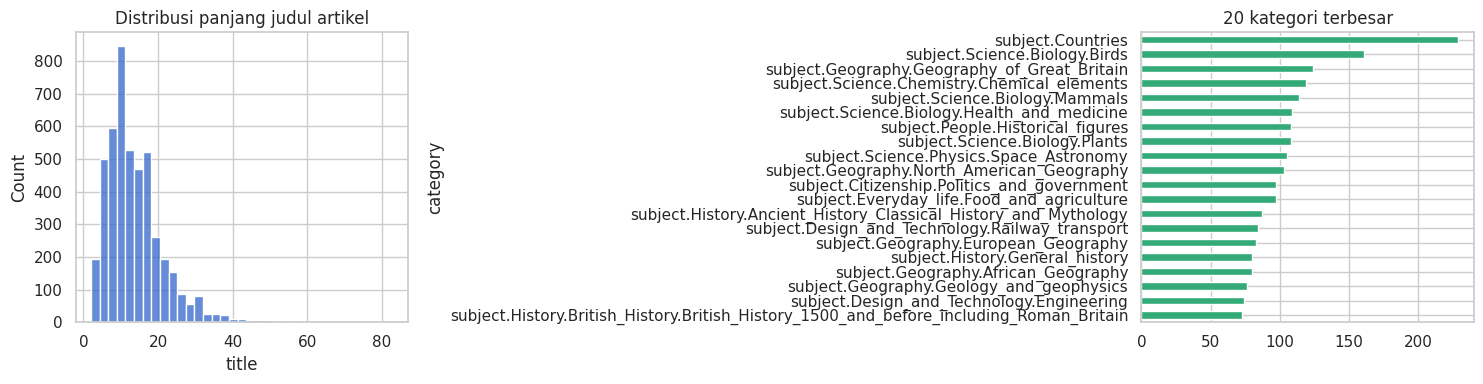

,category,articles
0,subject.Countries,229
1,subject.Science.Biology.Birds,161
2,subject.Geography.Geography_of_Great_Britain,124
3,subject.Science.Chemistry.Chemical_elements,119
4,subject.Science.Biology.Mammals,114
5,subject.Science.Biology.Health_and_medicine,109
6,subject.People.Historical_figures,108
7,subject.Science.Biology.Plants,108
8,subject.Science.Physics.Space_Astronomy,105
9,subject.Geography.North_American_Geography,103


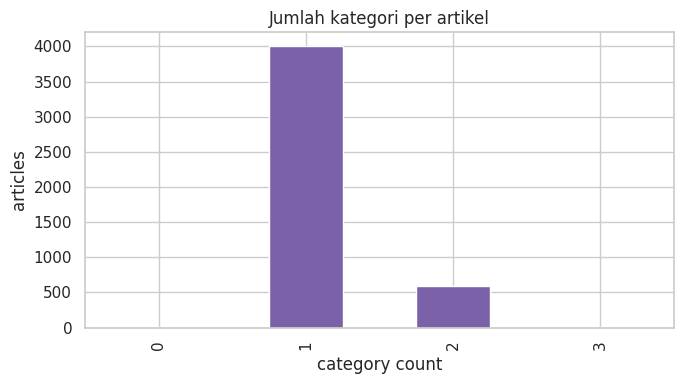

INSIGHT ARTICLE: 4598/4604 artikel memiliki kategori; 598 artikel multi-category. Median panjang title=12 karakter, sehingga title/category layak menjadi semantic feature yang compact.


In [4]:
title_len = articles.title.fillna('').str.len()
category_per_article = categories.groupby('article_id').category.nunique().reindex(articles.article_id, fill_value=0)
article_eda = pd.DataFrame({
    'metric': ['title_length_mean','title_length_median','title_length_max','articles_with_category','multi_category_articles','max_categories_per_article'],
    'value': [title_len.mean(), title_len.median(), title_len.max(), (category_per_article>0).sum(), (category_per_article>1).sum(), category_per_article.max()]
})
display(article_eda)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(title_len, bins=35, ax=ax[0], color='#3366cc'); ax[0].set_title('Distribusi panjang judul artikel')
categories.category.value_counts().head(20).sort_values().plot.barh(ax=ax[1], color='#33aa77'); ax[1].set_title('20 kategori terbesar')
plt.tight_layout(); plt.show()
display(categories.category.value_counts().head(15).rename_axis('category').reset_index(name='articles'))
fig, ax = plt.subplots(figsize=(7,4))
category_per_article.value_counts().sort_index().plot.bar(ax=ax,color='#7b61a8'); ax.set_title('Jumlah kategori per artikel'); ax.set_xlabel('category count'); ax.set_ylabel('articles'); plt.tight_layout(); plt.show()
print(f"INSIGHT ARTICLE: {int((category_per_article>0).sum())}/{len(articles)} artikel memiliki kategori; {int((category_per_article>1).sum())} artikel multi-category. Median panjang title={title_len.median():.0f} karakter, sehingga title/category layak menjadi semantic feature yang compact.")


## 4. EDA struktur state, target, current, dan label

Bagian ini mencari pola split dan skew label. Hal ini penting karena popularity baseline dapat terlihat kuat, tetapi belum tentu generalize ke target baru.


,value
unique_train_targets,360
unique_test_targets,240
target_overlap,0
states_per_train_target,[25]
states_per_test_target,[25]
unique_train_currents,3866
unique_test_currents,3312
test_rows_with_unseen_current,755
unique_next_labels,1023
direct_target_rate,0.007444


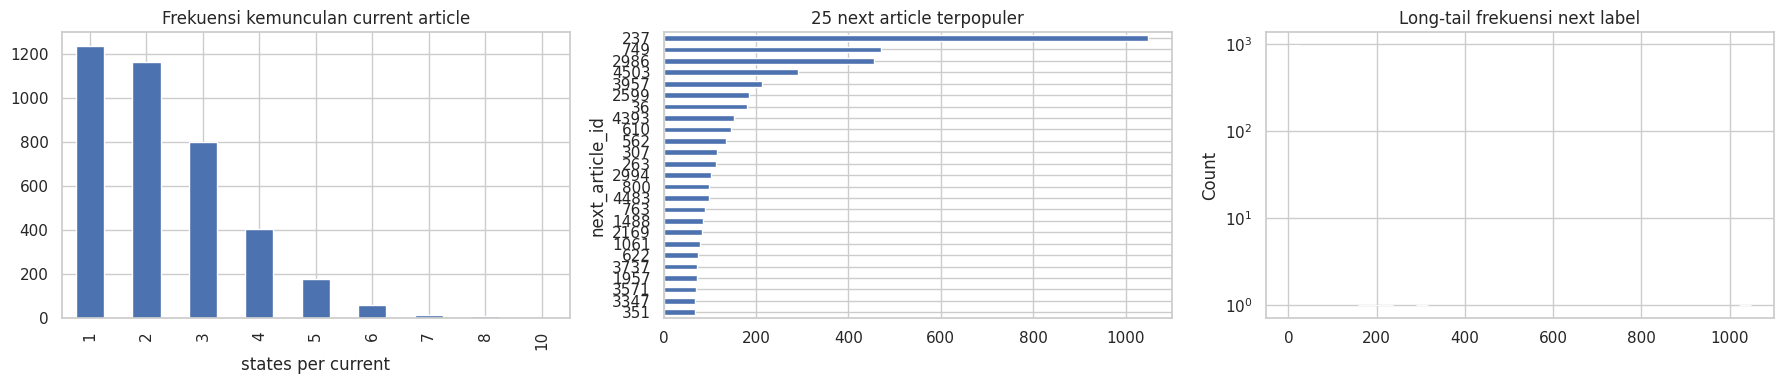

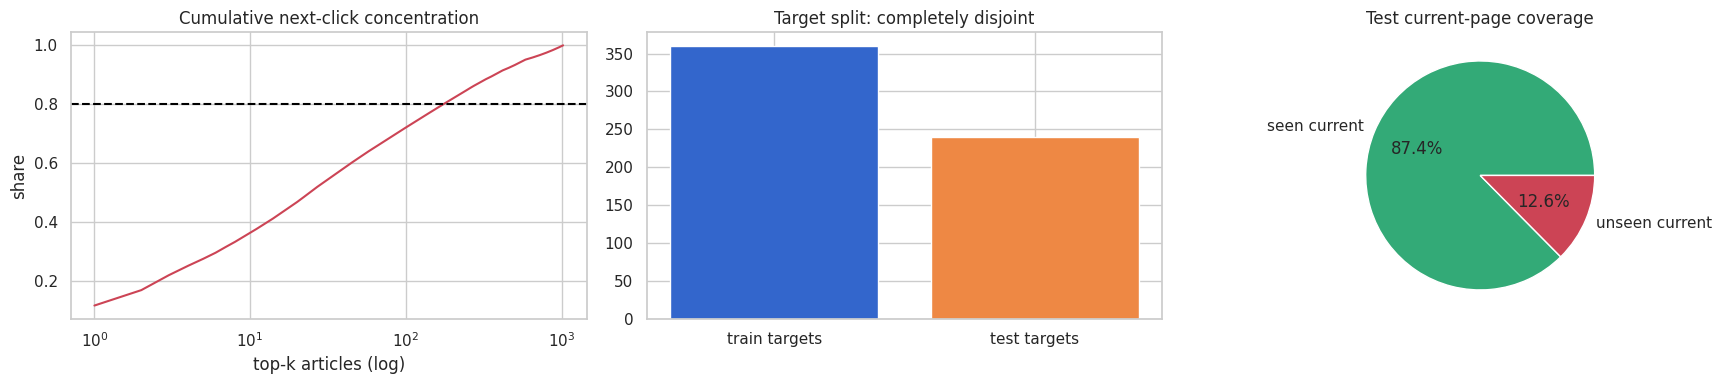

INSIGHT STATE: train/test targets tidak overlap; 755 test states memakai unseen current. Top-10 next articles mencakup 36.4% label, jadi popularity wajib menjadi baseline tetapi tidak cukup untuk unseen-current routing.


In [5]:
train_targets = set(train.target_article_id); test_targets = set(test.target_article_id)
train_currents = set(train.current_article_id); test_currents = set(test.current_article_id)
target_train_counts = train.target_article_id.value_counts(); target_test_counts = test.target_article_id.value_counts()
next_counts = train.next_article_id.value_counts()

state_eda = pd.Series({
    'unique_train_targets': len(train_targets), 'unique_test_targets': len(test_targets),
    'target_overlap': len(train_targets & test_targets),
    'states_per_train_target': sorted(target_train_counts.unique().tolist()),
    'states_per_test_target': sorted(target_test_counts.unique().tolist()),
    'unique_train_currents': len(train_currents), 'unique_test_currents': len(test_currents),
    'test_rows_with_unseen_current': int((~test.current_article_id.isin(train_currents)).sum()),
    'unique_next_labels': train.next_article_id.nunique(),
    'direct_target_rate': (train.next_article_id == train.target_article_id).mean(),
    'next_equals_current_rate': (train.next_article_id == train.current_article_id).mean(),
})
display(state_eda.to_frame('value'))

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
train.current_article_id.value_counts().value_counts().sort_index().plot.bar(ax=ax[0]); ax[0].set_title('Frekuensi kemunculan current article'); ax[0].set_xlabel('states per current')
next_counts.head(25).sort_values().plot.barh(ax=ax[1]); ax[1].set_title('25 next article terpopuler')
sns.histplot(next_counts.values, bins=40, log_scale=(False, True), ax=ax[2]); ax[2].set_title('Long-tail frekuensi next label')
plt.tight_layout(); plt.show()
cum_share = next_counts.cumsum()/next_counts.sum()
fig, ax = plt.subplots(1,3,figsize=(18,4))
ax[0].plot(np.arange(1,len(cum_share)+1),cum_share.values,color='#cc4455'); ax[0].axhline(.8,ls='--',color='black'); ax[0].set_xscale('log'); ax[0].set_title('Cumulative next-click concentration'); ax[0].set_xlabel('top-k articles (log)'); ax[0].set_ylabel('share')
ax[1].bar(['train targets','test targets'],[len(train_targets),len(test_targets)],color=['#3366cc','#ee8844']); ax[1].set_title('Target split: completely disjoint')
seen_rows=int(test.current_article_id.isin(train_currents).sum()); unseen_rows=len(test)-seen_rows
ax[2].pie([seen_rows,unseen_rows],labels=['seen current','unseen current'],autopct='%1.1f%%',colors=['#33aa77','#cc4455']); ax[2].set_title('Test current-page coverage')
plt.tight_layout(); plt.show()
top10_share=next_counts.head(10).sum()/len(train); print(f"INSIGHT STATE: train/test targets tidak overlap; {unseen_rows} test states memakai unseen current. Top-10 next articles mencakup {top10_share:.1%} label, jadi popularity wajib menjadi baseline tetapi tidak cukup untuk unseen-current routing.")


## 5. Split/leakage analysis dan validation design

Test target sepenuhnya berbeda dari train target. Karena setiap target mempunyai 25 state, random row split akan membocorkan identitas dan semantic target. V1 menggunakan `GroupKFold(target_article_id)` untuk semua perbandingan model.


,value
unique_train_current_target_pairs,9000
unique_test_current_target_pairs,6000
pair_overlap,0
target_overlap,0
current_overlap,2866


,states,targets,currents
fold,,,
0,3000,120,2142
1,3000,120,2196
2,3000,120,2174


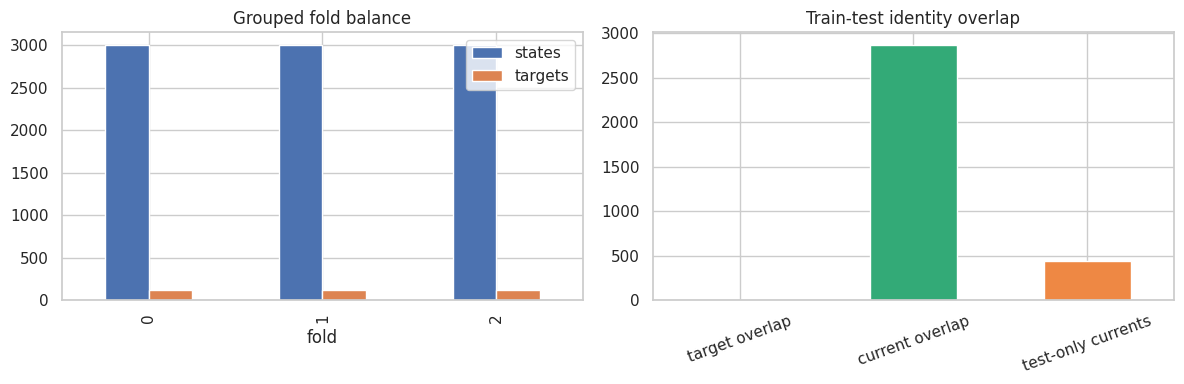

INSIGHT VALIDATION: setiap fold berisi 120 target dan 3.000 states. Grouping target adalah syarat utama untuk mencegah target-semantic leakage.


In [6]:
train_pairs = set(zip(train.current_article_id, train.target_article_id))
test_pairs = set(zip(test.current_article_id, test.target_article_id))
pair_audit = pd.Series({
    'unique_train_current_target_pairs': len(train_pairs),
    'unique_test_current_target_pairs': len(test_pairs),
    'pair_overlap': len(train_pairs & test_pairs),
    'target_overlap': len(train_targets & test_targets),
    'current_overlap': len(train_currents & test_currents),
}).to_frame('value')
display(pair_audit)
assert len(train_targets & test_targets) == 0
assert target_train_counts.nunique() == target_test_counts.nunique() == 1

gkf = GroupKFold(n_splits=N_SPLITS)
fold_id = np.full(len(train), -1, dtype=int)
for fold, (_, va_idx) in enumerate(gkf.split(train, groups=train.target_article_id)):
    fold_id[va_idx] = fold
train['fold'] = fold_id
fold_summary = train.groupby('fold').agg(states=('state_id','size'), targets=('target_article_id','nunique'), currents=('current_article_id','nunique'))
display(fold_summary); assert (fold_id >= 0).all()
fig, ax = plt.subplots(1,2,figsize=(12,4))
fold_summary[['states','targets']].plot.bar(ax=ax[0]); ax[0].set_title('Grouped fold balance'); ax[0].set_xlabel('fold')
overlap_plot=pd.Series({'target overlap':len(train_targets&test_targets),'current overlap':len(train_currents&test_currents),'test-only currents':len(test_currents-train_currents)})
overlap_plot.plot.bar(ax=ax[1],color=['#cc4455','#33aa77','#ee8844']); ax[1].set_title('Train-test identity overlap'); ax[1].tick_params(axis='x',rotation=20)
plt.tight_layout(); plt.show()
print('INSIGHT VALIDATION: setiap fold berisi 120 target dan 3.000 states. Grouping target adalah syarat utama untuk mencegah target-semantic leakage.')


## 6. EDA screenshot dan visual encoding link

Screenshot memiliki lebar tetap tetapi tinggi sangat bervariasi. Link berwarna biru merupakan sinyal utama. Kita sampling dimensi dan blue-pixel density untuk mengestimasi biaya OCR serta memilih preprocessing yang sesuai.


Sampling screenshots:   0%|          | 0/300 [00:00<?, ?it/s]

,count,mean,std,min,50%,90%,95%,99%,max
article_id,300.0,2301.003333,1335.445255,0.0000,2301.000000,4142.500000,4372.75000,4556.160000,4603.000000
width,300.0,900.000000,0.000000,900.0000,900.000000,900.000000,900.00000,900.000000,900.000000
height,300.0,7051.900000,6128.766836,422.0000,5267.000000,15551.000000,19635.50000,26405.000000,31472.000000
megapixels,300.0,6.346710,5.515890,0.3798,4.740300,13.995900,17.67195,23.764500,28.324800
blue_pixel_rate,300.0,0.003277,0.002833,0.0000,0.002686,0.005839,0.00714,0.017095,0.021801


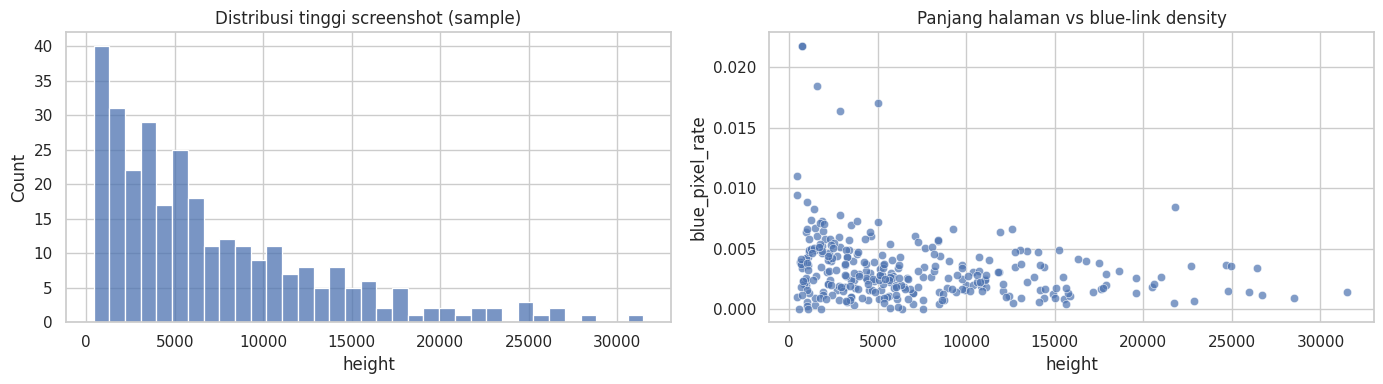

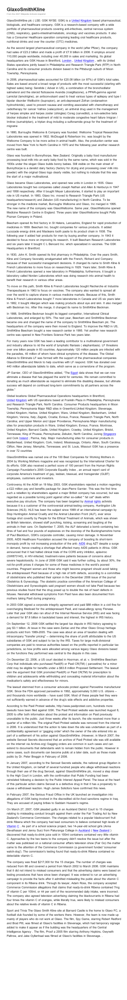

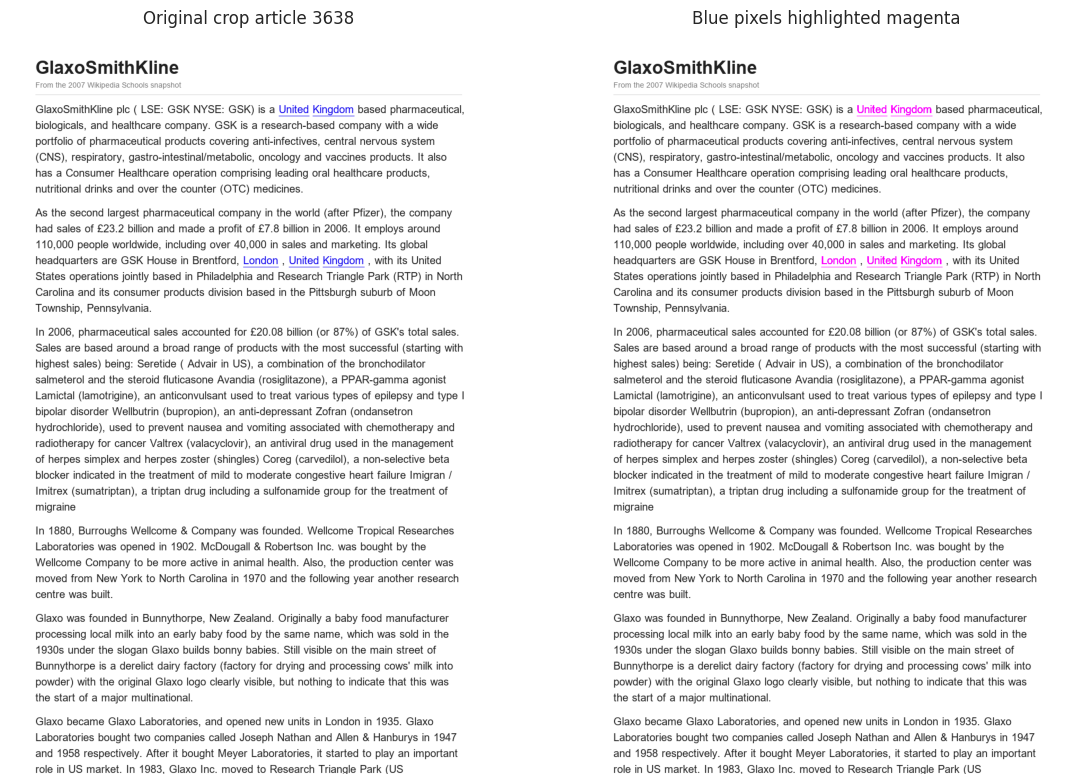

INSIGHT SCREENSHOT: lebar konsisten 900 px, tetapi tinggi sample p50=5267 dan p95=19636 px. Karena blue-pixel rate hanya 0.328%, color masking jauh lebih efisien daripada OCR seluruh body text.
[runtime] screenshot EDA: 0.77 min cumulative


In [7]:
sample_n = 60 if FAST_MODE else 300
sample_ids = np.linspace(0, len(articles)-1, sample_n, dtype=int)
image_rows = []
for aid in tqdm(sample_ids, desc='Sampling screenshots'):
    path = SCREENSHOT_DIR / f'{aid}.png'
    with Image.open(path) as im:
        rgb = np.asarray(im.convert('RGB'))
        r, g, b = rgb[...,0], rgb[...,1], rgb[...,2]
        blue = (b > 135) & ((b.astype(np.int16)-r) > 60) & ((b.astype(np.int16)-g) > 35)
        image_rows.append({'article_id': aid, 'width': im.width, 'height': im.height, 'megapixels': im.width*im.height/1e6, 'blue_pixel_rate': blue.mean()})
image_eda = pd.DataFrame(image_rows)
display(image_eda.describe(percentiles=[.5,.9,.95,.99]).T)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(image_eda.height, bins=35, ax=ax[0]); ax[0].set_title('Distribusi tinggi screenshot (sample)')
sns.scatterplot(data=image_eda, x='height', y='blue_pixel_rate', ax=ax[1], alpha=.7); ax[1].set_title('Panjang halaman vs blue-link density')
plt.tight_layout(); plt.show()

example_id = int(train.current_article_id.iloc[0])
with Image.open(SCREENSHOT_DIR / f'{example_id}.png') as im:
    preview = im.copy(); preview.thumbnail((700, 1000)); display(preview)
with Image.open(SCREENSHOT_DIR / f'{example_id}.png') as im:
    rgb=np.asarray(im.convert('RGB')); r,g,b=[rgb[...,i].astype(np.int16) for i in range(3)]; blue=(b>135)&(b-r>60)&(b-g>35)
    crop_h=min(1400,rgb.shape[0]); overlay=rgb[:crop_h].copy(); overlay[blue[:crop_h]]=[255,0,255]
fig,ax=plt.subplots(1,2,figsize=(12,8)); ax[0].imshow(rgb[:crop_h]); ax[0].set_title(f'Original crop article {example_id}'); ax[1].imshow(overlay); ax[1].set_title('Blue pixels highlighted magenta')
for a in ax:a.axis('off')
plt.tight_layout(); plt.show()
print(f"INSIGHT SCREENSHOT: lebar konsisten {int(image_eda.width.mode()[0])} px, tetapi tinggi sample p50={image_eda.height.median():.0f} dan p95={image_eda.height.quantile(.95):.0f} px. Karena blue-pixel rate hanya {image_eda.blue_pixel_rate.mean():.3%}, color masking jauh lebih efisien daripada OCR seluruh body text.")
stage('screenshot EDA')


## 7. Title normalization dan fuzzy matcher

Hasil OCR jarang identik sempurna dengan judul. Matcher menggunakan exact normalized title terlebih dahulu, lalu membatasi fuzzy search pada judul yang berbagi token agar tetap cepat dan mengurangi false match.


In [8]:
def normalize_text(text):
    text = unicodedata.normalize('NFKD', str(text)).encode('ascii', 'ignore').decode().lower()
    return re.sub(r'[^a-z0-9]+', ' ', text).strip()

id_to_title = articles.set_index('article_id').title.astype(str).to_dict()
normalized_title = {aid: normalize_text(title) for aid, title in id_to_title.items()}
exact_title_map = defaultdict(list)
token_to_ids = defaultdict(set)
for aid, norm in normalized_title.items():
    exact_title_map[norm].append(aid)
    for token in set(norm.split()):
        if len(token) >= 3: token_to_ids[token].add(aid)

def match_title(ocr_text, min_score=0.72):
    norm = normalize_text(ocr_text)
    if len(norm) < 2: return None, 0.0
    if norm in exact_title_map: return int(exact_title_map[norm][0]), 1.0
    pool = set()
    for token in norm.split():
        if len(token) >= 3: pool.update(token_to_ids.get(token, ()))
    if not pool: return None, 0.0
    scored = sorted(((SequenceMatcher(None, norm, normalized_title[aid]).ratio(), aid) for aid in pool), reverse=True)
    best_score, best_id = scored[0]
    margin = best_score - (scored[1][0] if len(scored) > 1 else 0)
    if best_score >= min_score and (best_score >= .86 or margin >= .04): return int(best_id), float(best_score)
    return None, float(best_score)

display(pd.DataFrame([{'text': t, 'match': match_title(t), 'expected_title': id_to_title[i]} for i,t in list(id_to_title.items())[:8]]))


,text,match,expected_title
0,Stratford-upon-Avon,"(0, 1.0)",Stratford-upon-Avon
1,"Dakota, Minnesota and Eastern Railroad","(1, 1.0)","Dakota, Minnesota and Eastern Railroad"
2,Miguel de Cervantes,"(2, 1.0)",Miguel de Cervantes
3,David Hume,"(3, 1.0)",David Hume
4,Marvin Gaye,"(4, 1.0)",Marvin Gaye
5,Claudius,"(5, 1.0)",Claudius
6,Space suit,"(6, 1.0)",Space suit
7,Porto-Novo,"(7, 1.0)",Porto-Novo


## 8. Blue-link region detection dan batched OCR

Deteksi warna mengisolasi glyph biru sebelum OCR, sehingga body text hitam tidak ikut diproses. Region dari satu halaman digabung menjadi contact sheet dan dibaca Tesseract secara batch. Jika OpenCV/Tesseract tidak tersedia, notebook tetap berjalan dengan transition priors dan semantic fallback, tetapi kualitas kandidat akan lebih rendah.


In [9]:
CV2_AVAILABLE = importlib.util.find_spec('cv2') is not None
TESSERACT_BIN = shutil.which('tesseract')
OCR_AVAILABLE = CV2_AVAILABLE and TESSERACT_BIN is not None
if CV2_AVAILABLE: import cv2
print({'cv2': CV2_AVAILABLE, 'tesseract': TESSERACT_BIN, 'ocr_enabled': OCR_AVAILABLE})

def blue_mask_and_boxes(image_path):
    rgb = np.asarray(Image.open(image_path).convert('RGB'))
    r, g, b = [rgb[...,i].astype(np.int16) for i in range(3)]
    mask = ((b > 135) & (b-r > 60) & (b-g > 35)).astype(np.uint8) * 255
    joined = cv2.dilate(mask, cv2.getStructuringElement(cv2.MORPH_RECT, (13, 3)), iterations=1)
    n, _, stats, _ = cv2.connectedComponentsWithStats(joined, connectivity=8)
    boxes = []
    for x, y, w, h, area in stats[1:]:
        ink = int((mask[y:y+h, x:x+w] > 0).sum())
        if 4 <= w <= 850 and 5 <= h <= 70 and ink >= 6:
            boxes.append((int(x), int(y), int(w), int(h)))
    return mask, sorted(boxes, key=lambda z: (z[1], z[0]))

def ocr_contact_sheet(mask, boxes, batch_size=36):
    outputs = []
    for start in range(0, len(boxes), batch_size):
        batch = boxes[start:start+batch_size]; tiles = []; heights = []
        for x,y,w,h in batch:
            crop = mask[max(0,y-3):y+h+3, max(0,x-3):x+w+3]
            tile = cv2.resize(255-crop, None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST)
            tiles.append(tile); heights.append(tile.shape[0] + 14)
        canvas = np.full((sum(heights), max(t.shape[1] for t in tiles)+20), 255, np.uint8)
        ranges = []; cursor = 0
        for tile, hh in zip(tiles, heights):
            canvas[cursor+7:cursor+7+tile.shape[0], 10:10+tile.shape[1]] = tile
            ranges.append((cursor, cursor+hh)); cursor += hh
        temp_path = None
        try:
            with tempfile.NamedTemporaryFile(suffix='.png', dir=CACHE_DIR, delete=False) as tmp: temp_path = Path(tmp.name)
            Image.fromarray(canvas).save(temp_path)
            cmd = [TESSERACT_BIN, str(temp_path), 'stdout', '--psm', '6', 'tsv']
            result = subprocess.run(cmd, capture_output=True, text=True, timeout=90)
            if result.returncode != 0: raise RuntimeError(result.stderr[-500:])
            data = pd.read_csv(io.StringIO(result.stdout), sep='\t').dropna(subset=['text'])
            data = data[data.conf.astype(float) >= 0]
            for lo, hi in ranges:
                part = data[((data.top + data.height/2) >= lo) & ((data.top + data.height/2) < hi)].sort_values('left')
                outputs.append((' '.join(part.text.astype(str)).strip(), float(part.conf.mean()) if len(part) else 0.0))
        finally:
            if temp_path is not None and temp_path.exists(): temp_path.unlink()
    return outputs

def extract_page_links(article_id):
    if not OCR_AVAILABLE: return [], []
    mask, boxes = blue_mask_and_boxes(SCREENSHOT_DIR / f'{article_id}.png')
    texts = ocr_contact_sheet(mask, boxes) if boxes else []
    rows, raw_rows = [], []
    page_height = mask.shape[0]
    for (x,y,w,h), (text, confidence) in zip(boxes, texts):
        candidate_id, match_score = match_title(text)
        accepted = candidate_id is not None and candidate_id != article_id
        status = 'accepted' if accepted else ('self_link' if candidate_id == article_id else 'unmatched')
        raw_rows.append({'source_id':int(article_id),'box_x':x,'box_y':y,'box_w':w,'box_h':h,'ocr_text':text,'ocr_confidence':confidence/100,'candidate_id':candidate_id,'candidate_title':id_to_title.get(candidate_id,''),'match_score':match_score,'position_y':y/max(page_height,1),'status':status})
        if accepted:
            rows.append({'source_id': int(article_id), 'candidate_id': candidate_id, 'ocr_text': text, 'ocr_confidence': confidence/100, 'match_score': match_score, 'position_y': y/max(page_height,1)})
    return rows, raw_rows


{'cv2': True, 'tesseract': '/usr/bin/tesseract', 'ocr_enabled': True}


## 9. Menjalankan/resume OCR dan menyimpan hyperlink cache

OCR adalah tahap paling lambat. Progress disimpan berkala sehingga run dapat dilanjutkan tanpa mengulang halaman yang sudah selesai. Selain candidate links untuk model, seluruh raw OCR region dan visual review sample disimpan ke reusable output. Full run memproses semua 4.604 halaman; `DATATON_OCR_PAGE_LIMIT` dapat dipakai untuk diagnostic run.


In [10]:
LINK_CACHE = CACHE_DIR / 'task2_v1_link_candidates.csv'
RAW_OCR_CACHE = CACHE_DIR / 'task2_v1_ocr_raw_regions.csv'
PROCESSED_CACHE = CACHE_DIR / 'task2_v1_ocr_processed.json'
LINK_COLUMNS = ['source_id','candidate_id','ocr_text','ocr_confidence','match_score','position_y']
RAW_COLUMNS = ['source_id','box_x','box_y','box_w','box_h','ocr_text','ocr_confidence','candidate_id','candidate_title','match_score','position_y','status']
if LINK_CACHE.exists() and LINK_CACHE.stat().st_size > 10:
    link_rows = pd.read_csv(LINK_CACHE).to_dict('records')
else:
    link_rows = []
raw_ocr_rows = pd.read_csv(RAW_OCR_CACHE).to_dict('records') if RAW_OCR_CACHE.exists() and RAW_OCR_CACHE.stat().st_size > 10 else []
processed_ids = set(json.loads(PROCESSED_CACHE.read_text())) if PROCESSED_CACHE.exists() else set()
page_ids = articles.article_id.astype(int).tolist()
if FAST_MODE and OCR_PAGE_LIMIT == 0: page_ids = sorted(set(train.current_article_id.head(250)) | set(test.current_article_id.head(150)))
if OCR_PAGE_LIMIT > 0: page_ids = page_ids[:OCR_PAGE_LIMIT]

if OCR_AVAILABLE:
    pending = [aid for aid in page_ids if aid not in processed_ids]
    for j, aid in enumerate(tqdm(pending, desc='Blue-link OCR')):
        try:
            accepted_rows, page_raw_rows = extract_page_links(aid)
            link_rows.extend(accepted_rows); raw_ocr_rows.extend(page_raw_rows)
        except Exception as exc:
            print(f'OCR warning article {aid}: {type(exc).__name__}: {exc}')
        processed_ids.add(aid)
        if (j+1) % OCR_CHECKPOINT_EVERY == 0:
            pd.DataFrame(link_rows, columns=LINK_COLUMNS).to_csv(LINK_CACHE, index=False)
            pd.DataFrame(raw_ocr_rows, columns=RAW_COLUMNS).to_csv(RAW_OCR_CACHE, index=False)
            PROCESSED_CACHE.write_text(json.dumps(sorted(processed_ids)))
    pd.DataFrame(link_rows, columns=LINK_COLUMNS).to_csv(LINK_CACHE, index=False)
    pd.DataFrame(raw_ocr_rows, columns=RAW_COLUMNS).to_csv(RAW_OCR_CACHE, index=False)
    PROCESSED_CACHE.write_text(json.dumps(sorted(processed_ids)))
else:
    print('OCR backend unavailable: continuing with supervised transitions and semantic fallback.')

links = pd.DataFrame(link_rows, columns=LINK_COLUMNS)
raw_ocr = pd.DataFrame(raw_ocr_rows, columns=RAW_COLUMNS)
if len(links):
    links = links.sort_values(['source_id','candidate_id','match_score'], ascending=[True,True,False]).drop_duplicates(['source_id','candidate_id'])
display(links.head(10)); print('Extracted directed links:', len(links), '| raw OCR regions:',len(raw_ocr),'| processed pages:', len(processed_ids))
OCR_QUALITY_PATH = REUSABLE_DIR/'task2_v1_ocr_quality_by_page.csv'
OCR_REVIEW_SAMPLE_PATH = REUSABLE_DIR/'task2_v1_ocr_manual_review_sample.csv'
if len(raw_ocr):
    raw_ocr['accepted'] = raw_ocr.status.eq('accepted')
    page_quality = raw_ocr.groupby('source_id').agg(regions=('status','size'),accepted_links=('accepted','sum'),accepted_rate=('accepted','mean'),mean_ocr_confidence=('ocr_confidence','mean'),mean_match_score=('match_score','mean')).reset_index()
    page_quality.to_csv(OCR_QUALITY_PATH,index=False)
    review_ids = []
    review_ids += page_quality.sort_values(['accepted_rate','regions']).source_id.head(3).astype(int).tolist()
    review_ids += page_quality.sort_values('regions',ascending=False).source_id.head(3).astype(int).tolist()
    review_ids += page_quality.sample(min(3,len(page_quality)),random_state=SEED).source_id.astype(int).tolist()
    review_ids = list(dict.fromkeys(review_ids))[:8]
    raw_ocr[raw_ocr.source_id.isin(review_ids)].to_csv(OCR_REVIEW_SAMPLE_PATH,index=False)
    for aid in review_ids:
        canvas = np.asarray(Image.open(SCREENSHOT_DIR/f'{aid}.png').convert('RGB')).copy()
        for rr in raw_ocr[raw_ocr.source_id==aid].itertuples(index=False):
            color=(0,180,0) if rr.status=='accepted' else (220,40,40)
            x,y,w,h=[int(getattr(rr,k)) for k in ['box_x','box_y','box_w','box_h']]
            cv2.rectangle(canvas,(x,y),(x+w,y+h),color,2)
            label=(str(rr.candidate_title) if rr.status=='accepted' else str(rr.ocr_text))[:42]
            cv2.putText(canvas,label,(x,max(12,y-3)),cv2.FONT_HERSHEY_SIMPLEX,.38,color,1,cv2.LINE_AA)
        Image.fromarray(canvas).save(OCR_REVIEW_DIR/f'article_{aid}_ocr_review.jpg',quality=78,optimize=True)
    display(page_quality.describe().T); print('Manual OCR review pages:',review_ids)
else:
    page_quality = pd.DataFrame(columns=['source_id','regions','accepted_links','accepted_rate','mean_ocr_confidence','mean_match_score'])
    page_quality.to_csv(OCR_QUALITY_PATH,index=False); pd.DataFrame(columns=RAW_COLUMNS).to_csv(OCR_REVIEW_SAMPLE_PATH,index=False)
stage('OCR/link extraction and review pack')


Blue-link OCR:   0%|          | 0/4604 [00:00<?, ?it/s]

,source_id,candidate_id,ocr_text,ocr_confidence,match_score,position_y
2,0,2765,William Shakespeare,0.910000,1.0,0.881078
0,0,3461,Birmingham,0.960000,1.0,0.143763
1,0,4483,London,0.960000,1.0,0.191332
4,1,237,United States,0.960000,1.0,0.033154
10,1,1975,President of the United States,0.958000,1.0,0.250252
7,1,2263,Chicago,0.960000,1.0,0.161898
17,1,2640,Canadian Pacific Railway,0.956667,1.0,0.734938
15,1,3120,Cereal,0.960000,1.0,0.707169
6,1,3198,Coal,0.950000,1.0,0.103837
16,1,3316,Wood,0.950000,1.0,0.712218


Extracted directed links: 93256 | raw OCR regions: 121460 | processed pages: 4604


,count,mean,std,min,25%,50%,75%,max
source_id,4546.0,2302.497800,1328.272058,0.00,1153.250000,2303.500000,3451.750000,4603.00
regions,4546.0,26.717994,27.055419,1.00,10.000000,19.000000,35.000000,370.00
accepted_links,4546.0,26.455785,26.677900,0.00,10.000000,19.000000,34.000000,347.00
accepted_rate,4546.0,0.990524,0.038178,0.00,1.000000,1.000000,1.000000,1.00
mean_ocr_confidence,4546.0,0.942480,0.027696,0.19,0.938742,0.950015,0.955982,0.97
mean_match_score,4546.0,0.992062,0.029046,0.00,0.995010,1.000000,1.000000,1.00


Manual OCR review pages: [1577, 508, 277, 1371, 749, 36, 479, 3822]
[runtime] OCR/link extraction and review pack: 46.55 min cumulative


## 10. Candidate recall dan hyperlink graph EDA

Candidate recall adalah batas atas ranker. Selain recall mentah OCR, kita mengukur coverage setelah menambahkan observed transitions dari train. Observed transitions sah untuk final training, tetapi pada OOF hanya transition dari fold-training yang boleh dipakai.


,value
directed_edges,93256.000000
pages_with_extracted_links,4545.000000
median_out_degree,16.000000
p95_out_degree,54.000000
raw_ocr_candidate_recall,0.978333
ocr_plus_foldsafe_transition_recall,0.983667


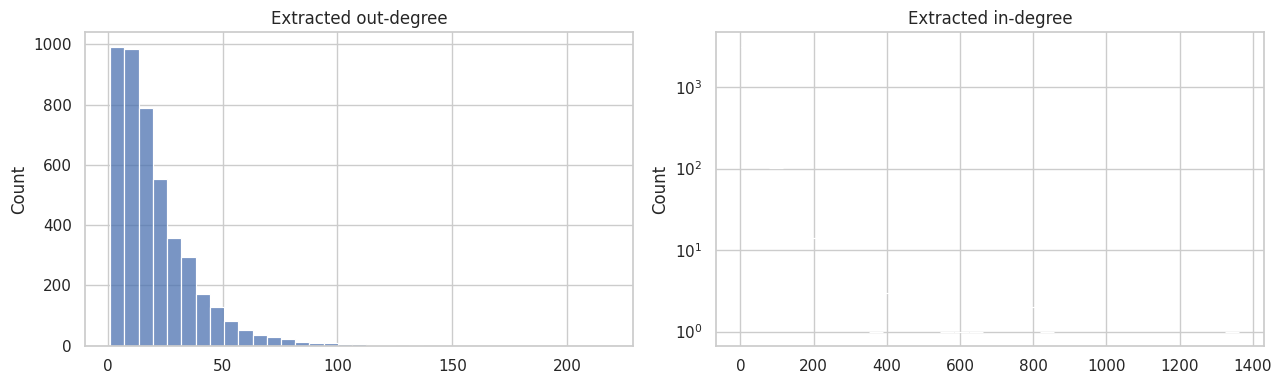

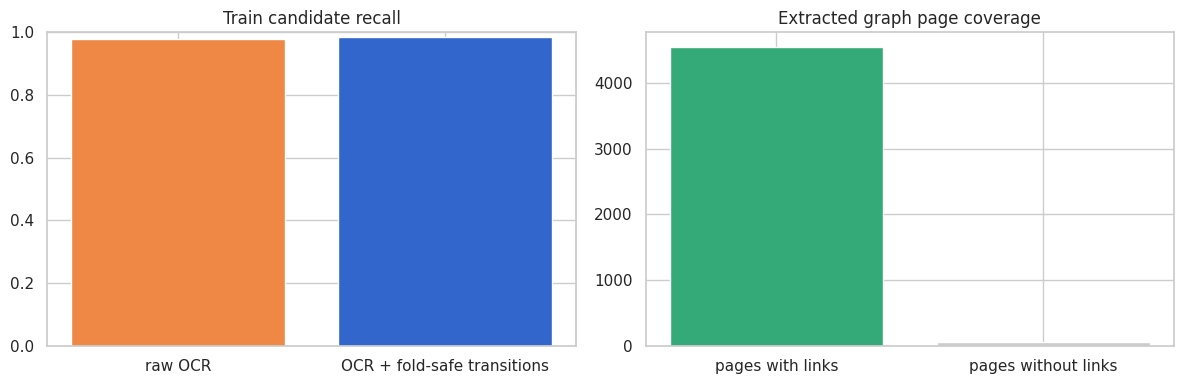

INSIGHT CANDIDATE: raw OCR recall=97.83%; setelah fold-safe transition augmentation=98.37%. Nilai recall adalah batas atas accuracy ranker dan harus menjadi diagnosis pertama pada full run.


In [11]:
ocr_candidates = defaultdict(set)
link_meta = {}
for row in links.itertuples(index=False):
    s, c = int(row.source_id), int(row.candidate_id)
    ocr_candidates[s].add(c)
    link_meta[(s,c)] = (float(row.ocr_confidence), float(row.match_score), float(row.position_y))
observed_full = defaultdict(set)
for row in train.itertuples(index=False): observed_full[int(row.current_article_id)].add(int(row.next_article_id))
raw_recall = np.mean([int(r.next_article_id) in ocr_candidates[int(r.current_article_id)] for r in train.itertuples(index=False)])
foldsafe_hits = []
for fold in sorted(train.fold.unique()):
    fit_part, val_part = train[train.fold != fold], train[train.fold == fold]
    fold_observed = defaultdict(set)
    for r in fit_part.itertuples(index=False): fold_observed[int(r.current_article_id)].add(int(r.next_article_id))
    foldsafe_hits.extend(int(r.next_article_id) in (ocr_candidates[int(r.current_article_id)] | fold_observed[int(r.current_article_id)]) for r in val_part.itertuples(index=False))
foldsafe_aug_recall = float(np.mean(foldsafe_hits))

out_degree = np.zeros(len(articles), dtype=np.int32); in_degree = np.zeros(len(articles), dtype=np.int32)
for s, cs in ocr_candidates.items():
    out_degree[s] = len(cs)
    for c in cs: in_degree[c] += 1
graph_eda = pd.Series({
    'directed_edges': int(out_degree.sum()), 'pages_with_extracted_links': int((out_degree>0).sum()),
    'median_out_degree': float(np.median(out_degree[out_degree>0])) if (out_degree>0).any() else 0,
    'p95_out_degree': float(np.percentile(out_degree[out_degree>0],95)) if (out_degree>0).any() else 0,
    'raw_ocr_candidate_recall': raw_recall, 'ocr_plus_foldsafe_transition_recall': foldsafe_aug_recall,
}).to_frame('value')
display(graph_eda)
fig, ax = plt.subplots(1,2,figsize=(13,4))
sns.histplot(out_degree[out_degree>0], bins=35, ax=ax[0]); ax[0].set_title('Extracted out-degree')
sns.histplot(in_degree[in_degree>0], bins=35, ax=ax[1], log_scale=(False,True)); ax[1].set_title('Extracted in-degree')
plt.tight_layout(); plt.show()
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].bar(['raw OCR','OCR + fold-safe transitions'],[raw_recall,foldsafe_aug_recall],color=['#ee8844','#3366cc']); ax[0].set_ylim(0,1); ax[0].set_title('Train candidate recall')
ax[1].bar(['pages with links','pages without links'],[(out_degree>0).sum(),(out_degree==0).sum()],color=['#33aa77','#cccccc']); ax[1].set_title('Extracted graph page coverage')
plt.tight_layout(); plt.show()
print(f"INSIGHT CANDIDATE: raw OCR recall={raw_recall:.2%}; setelah fold-safe transition augmentation={foldsafe_aug_recall:.2%}. Nilai recall adalah batas atas accuracy ranker dan harus menjadi diagnosis pertama pada full run.")


## 11. Semantic article representation

Title dan category digabung menjadi dokumen pendek, lalu diubah menjadi word+character TF-IDF. Character n-gram membantu variasi ejaan/OCR, sedangkan category memberi coarse semantic direction untuk unseen target.


In [12]:
category_lists = categories.groupby('article_id').category.apply(list).to_dict()
category_sets = {aid: set(category_lists.get(aid, [])) for aid in article_ids}
article_docs = []
for aid in articles.article_id:
    cats = ' '.join(str(x).replace('subject.',' ').replace('.',' ') for x in category_lists.get(aid, []))
    article_docs.append(f"{id_to_title[aid]} {id_to_title[aid]} {cats}")
word_vec = TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=1, sublinear_tf=True)
char_vec = TfidfVectorizer(lowercase=True, analyzer='char_wb', ngram_range=(2,5), min_df=2, sublinear_tf=True, max_features=30000)
WORD_X = word_vec.fit_transform(article_docs); CHAR_X = char_vec.fit_transform(article_docs)
print('Word TF-IDF:', WORD_X.shape, '| char TF-IDF:', CHAR_X.shape)

def sparse_cosine(matrix, candidates, target):
    if len(candidates) == 0: return np.empty(0, dtype=np.float32)
    return np.asarray(matrix[np.asarray(candidates)].multiply(matrix[int(target)]).sum(axis=1)).ravel().astype(np.float32)

def category_jaccard(candidate, target):
    a, b = category_sets.get(int(candidate), set()), category_sets.get(int(target), set())
    return len(a & b) / len(a | b) if (a or b) else 0.0


Word TF-IDF: (4604, 17697) | char TF-IDF: (4604, 19068)


## 12. Directed graph distance features

Untuk setiap target, reverse BFS menghitung berapa click minimum dari seluruh artikel menuju target pada graph hasil OCR. Distance dipakai sebagai feature, bukan dianggap ground truth, karena OCR graph dapat tidak lengkap.


Target BFS diagnostics:   0%|          | 0/600 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
target,600.0,2356.346667,1337.078738,2.0,1185.5,2372.5,3521.0,4598.0
reachable_nodes,600.0,4537.435000,185.385694,4.0,4545.0,4545.0,4545.0,4546.0
median_distance,600.0,3.195000,0.586699,1.0,3.0,3.0,3.0,6.0


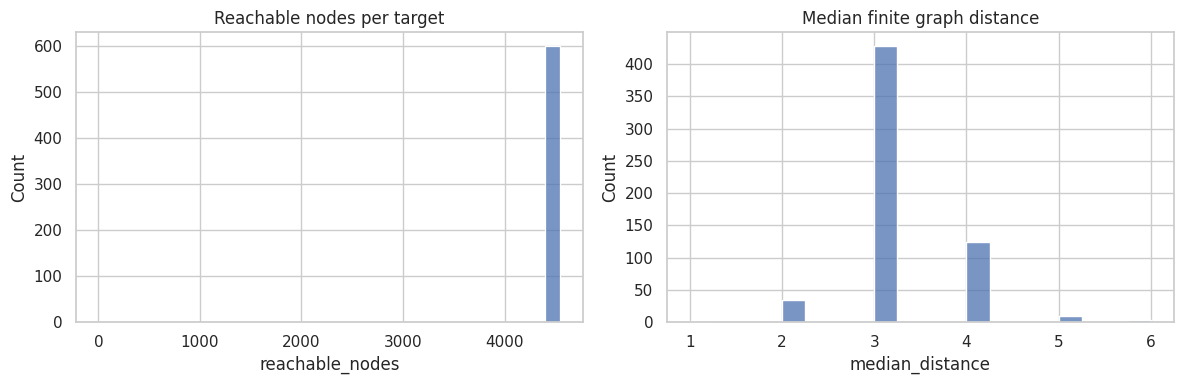

INSIGHT GRAPH: median target dapat dijangkau dari 4545 nodes pada extracted graph. Jika angka ini rendah pada full run, graph-distance feature harus dianggap weak/noisy dan semantic features menjadi fallback utama.
[runtime] semantic and graph features: 46.73 min cumulative


In [13]:
N_ARTICLES = int(articles.article_id.max()) + 1
reverse_adj = [[] for _ in range(N_ARTICLES)]
for source, candidates in ocr_candidates.items():
    for candidate in candidates: reverse_adj[candidate].append(source)
DIST_CACHE = {}

def distances_to_target(target):
    target = int(target)
    if target in DIST_CACHE: return DIST_CACHE[target]
    dist = np.full(N_ARTICLES, 99, dtype=np.int16); dist[target] = 0
    q = deque([target])
    while q:
        node = q.popleft(); nd = int(dist[node]) + 1
        for prev in reverse_adj[node]:
            if dist[prev] == 99: dist[prev] = nd; q.append(prev)
    DIST_CACHE[target] = dist
    return dist

target_reachability = []
for target in tqdm(sorted(train_targets | test_targets), desc='Target BFS diagnostics'):
    d = distances_to_target(target); target_reachability.append({'target':target, 'reachable_nodes':int((d<99).sum()), 'median_distance':float(np.median(d[d<99]))})
reach_df = pd.DataFrame(target_reachability)
display(reach_df.describe().T)
fig,ax=plt.subplots(1,2,figsize=(12,4)); sns.histplot(reach_df.reachable_nodes,bins=30,ax=ax[0]); ax[0].set_title('Reachable nodes per target'); sns.histplot(reach_df.median_distance,bins=20,ax=ax[1]); ax[1].set_title('Median finite graph distance'); plt.tight_layout(); plt.show()
print(f"INSIGHT GRAPH: median target dapat dijangkau dari {reach_df.reachable_nodes.median():.0f} nodes pada extracted graph. Jika angka ini rendah pada full run, graph-distance feature harus dianggap weak/noisy dan semantic features menjadi fallback utama.")
stage('semantic and graph features')


## 13. Candidate generation dan fold-safe priors

Candidate set menggabungkan link OCR dan observed transitions dari data training fold. True label hanya ditambahkan ketika membentuk pair training, tidak saat validation/test. Jika tidak ada candidate, fallback memakai target serta next article populer agar notebook tetap menghasilkan prediksi.


In [14]:
def fit_priors(frame):
    global_counts = Counter(frame.next_article_id.astype(int))
    current_counts = defaultdict(Counter)
    for r in frame.itertuples(index=False): current_counts[int(r.current_article_id)][int(r.next_article_id)] += 1
    observed = {c:set(counter) for c,counter in current_counts.items()}
    global_top = [x for x,_ in global_counts.most_common(30)]
    return global_counts, current_counts, observed, global_top

def candidate_pool(current, target, observed, global_top, max_candidates, truth=None):
    current, target = int(current), int(target)
    candidates = set(ocr_candidates.get(current, set())) | set(observed.get(current, set()))
    if not candidates: candidates = set(global_top[:20]) | {target}
    if truth is not None: candidates.add(int(truth))
    def priority(c):
        conf, match, pos = link_meta.get((current,c), (0,0,1))
        return (c == truth, c == target, c in observed.get(current,set()), match, conf, -pos)
    ranked = sorted(candidates, key=priority, reverse=True)
    return ranked[:max_candidates]

FEATURE_NAMES = ['direct_target','word_cosine','char_cosine','category_jaccard','graph_distance','graph_improvement','ocr_confidence','title_match','link_position','log_global_clicks','log_current_clicks','observed_edge','log_out_degree','log_in_degree']


## 14. Pairwise feature engineering

Setiap state diubah menjadi beberapa row `(state, candidate)`. Label pair bernilai satu hanya untuk next article yang benar. Feature mencampur semantic similarity, graph routing, OCR quality, position, dan click priors.


In [15]:
def build_pairs(frame, priors, add_truth, max_candidates):
    global_counts, current_counts, observed, global_top = priors
    feature_blocks, labels, meta_rows = [], [], []
    has_label = 'next_article_id' in frame.columns
    for row in tqdm(frame.itertuples(index=False), total=len(frame), desc='Pair features', leave=False):
        current, target = int(row.current_article_id), int(row.target_article_id)
        truth = int(row.next_article_id) if has_label else None
        candidates = candidate_pool(current, target, observed, global_top, max_candidates, truth if add_truth else None)
        cands = np.asarray(candidates, dtype=int); n = len(cands)
        word_sim = sparse_cosine(WORD_X, cands, target); char_sim = sparse_cosine(CHAR_X, cands, target)
        dist = distances_to_target(target); current_dist = min(int(dist[current]), 20)
        block = np.zeros((n, len(FEATURE_NAMES)), dtype=np.float32)
        for j, cand in enumerate(candidates):
            conf, match, pos = link_meta.get((current,cand), (0.0,0.0,1.0))
            cd = min(int(dist[cand]), 20)
            block[j] = [
                cand == target, word_sim[j], char_sim[j], category_jaccard(cand,target), cd, current_dist-cd,
                conf, match, pos, math.log1p(global_counts.get(cand,0)), math.log1p(current_counts.get(current,{}).get(cand,0)),
                cand in observed.get(current,set()), math.log1p(out_degree[cand]), math.log1p(in_degree[cand])
            ]
            labels.append(int(truth is not None and cand == truth))
            meta_rows.append({'state_id':int(row.state_id),'candidate_id':cand,'truth':truth,'current':current,'target':target})
        feature_blocks.append(block)
    X = np.vstack(feature_blocks) if feature_blocks else np.empty((0,len(FEATURE_NAMES)),np.float32)
    return X, np.asarray(labels,dtype=np.int8), pd.DataFrame(meta_rows)

def heuristic_score(X):
    f = {name:X[:,i] for i,name in enumerate(FEATURE_NAMES)}
    return (3.0*f['direct_target'] + 1.1*f['word_cosine'] + 1.6*f['char_cosine'] + .9*f['category_jaccard'] - .20*f['graph_distance'] + .45*f['graph_improvement'] + .18*f['log_current_clicks'] + .05*f['log_global_clicks'] + .08*f['title_match'] - .03*f['link_position'])

def rank_normalize(meta, scores):
    temp = pd.DataFrame({'state_id':meta.state_id.values,'score':scores})
    return temp.groupby('state_id').score.rank(method='average', pct=True).to_numpy(np.float32)

def evaluate_pair_scores(meta, scores):
    work = meta[['state_id','candidate_id','truth']].copy(); work['score'] = scores
    winners = work.sort_values(['state_id','score','candidate_id'], ascending=[True,False,True]).drop_duplicates('state_id')
    ranked = work.sort_values(['state_id','score','candidate_id'], ascending=[True,False,True]).copy()
    ranked['rank'] = ranked.groupby('state_id').cumcount() + 1
    accuracy = (winners.candidate_id == winners.truth).mean()
    recall = work.assign(hit=work.candidate_id==work.truth).groupby('state_id').hit.max().mean()
    top3 = ranked.assign(hit=(ranked.candidate_id==ranked.truth)&(ranked['rank']<=3)).groupby('state_id').hit.max().mean()
    top5 = ranked.assign(hit=(ranked.candidate_id==ranked.truth)&(ranked['rank']<=5)).groupby('state_id').hit.max().mean()
    return float(accuracy), float(top3), float(top5), float(recall), winners[['state_id','candidate_id','truth','score']]


## 15. Baseline dan grouped out-of-fold model comparison

V1 membandingkan global popularity, current-page majority, handcrafted heuristic, logistic regression, histogram gradient boosting, dan fixed rank ensemble. Priors selalu dihitung hanya dari fold-training.


Pair features:   0%|          | 0/6000 [00:00<?, ?it/s]

Pair features:   0%|          | 0/3000 [00:00<?, ?it/s]

Fold 0 complete | train pairs=113,507 val pairs=61,911


Pair features:   0%|          | 0/6000 [00:00<?, ?it/s]

Pair features:   0%|          | 0/3000 [00:00<?, ?it/s]

Fold 1 complete | train pairs=113,285 val pairs=62,021


Pair features:   0%|          | 0/6000 [00:00<?, ?it/s]

Pair features:   0%|          | 0/3000 [00:00<?, ?it/s]

Fold 2 complete | train pairs=113,171 val pairs=63,119


fold,0,1,2
model,,,
current_mode,0.248000,0.230000,0.236333
current_ranker_fallback,0.390667,0.386000,0.383333
global_mode,0.118000,0.106000,0.125333
heuristic,0.663000,0.634667,0.655000
hist_gbdt,0.291667,0.276333,0.291667
logistic,0.436667,0.438333,0.440000
rank_ensemble,0.428000,0.426667,0.431000


,mean_accuracy,std_accuracy,mean_top3,mean_top5,mean_candidate_recall
model,,,,,
heuristic,0.650889,0.014607,0.899111,0.948000,0.981778
logistic,0.438333,0.001667,0.834444,0.937556,0.981778
rank_ensemble,0.428556,0.002219,0.835333,0.939333,0.981778
current_ranker_fallback,0.386667,0.003712,0.835333,0.939333,0.981778
hist_gbdt,0.286556,0.008853,0.444333,0.552556,0.981778
current_mode,0.238111,0.009131,NaN,NaN,NaN
global_mode,0.116444,0.009760,NaN,NaN,NaN


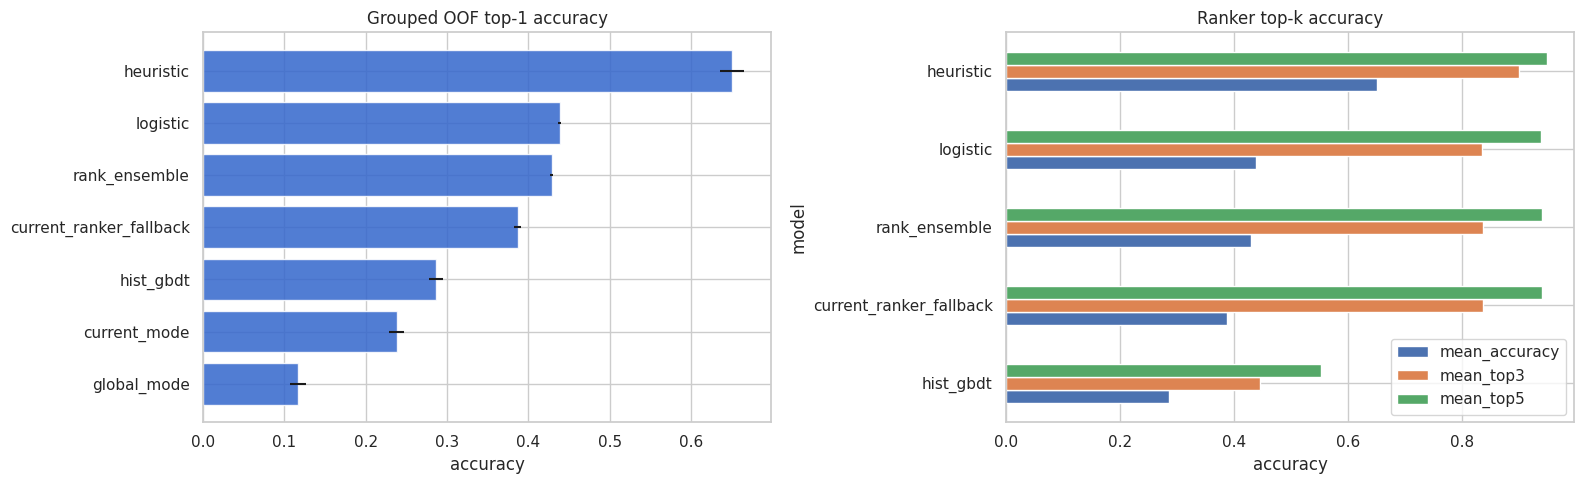

INSIGHT CV: model terbaik sementara=heuristic dengan grouped accuracy=0.6509. Candidate recall ranker harus dibaca bersama top-1 agar kegagalan extraction dan ranking tidak tercampur.
[runtime] grouped OOF models: 47.25 min cumulative


In [16]:
train_work = train.copy()
if FAST_MODE: train_work = train_work.groupby('target_article_id', group_keys=False).head(4).reset_index(drop=True)
fold_rows, oof_winners, fold_models = [], [], []
splitter = GroupKFold(n_splits=N_SPLITS)

for fold, (tr_idx, va_idx) in enumerate(splitter.split(train_work, groups=train_work.target_article_id)):
    fit_df = train_work.iloc[tr_idx].copy(); val_df = train_work.iloc[va_idx].copy()
    priors = fit_priors(fit_df); global_counts, current_counts, observed, global_top = priors
    global_mode = global_top[0]
    global_acc = (val_df.next_article_id == global_mode).mean()
    current_pred = [current_counts.get(int(c), Counter()).most_common(1)[0][0] if current_counts.get(int(c)) else global_mode for c in val_df.current_article_id]
    current_acc = np.mean(np.asarray(current_pred) == val_df.next_article_id.to_numpy())

    X_tr, y_tr, meta_tr = build_pairs(fit_df, priors, True, MAX_TRAIN_CANDIDATES)
    X_va, y_va, meta_va = build_pairs(val_df, priors, False, MAX_EVAL_CANDIDATES)
    pos_weight = max((len(y_tr)-y_tr.sum())/max(y_tr.sum(),1), 1)
    sample_weight = np.where(y_tr==1, pos_weight, 1.0)

    logit = LogisticRegression(C=1.0, max_iter=300, solver='liblinear', random_state=SEED+fold)
    logit.fit(X_tr, y_tr, sample_weight=sample_weight)
    hgb = HistGradientBoostingClassifier(max_iter=140 if not FAST_MODE else 35, learning_rate=.07, max_leaf_nodes=31, min_samples_leaf=25, l2_regularization=2.0, random_state=SEED+fold)
    hgb.fit(X_tr, y_tr, sample_weight=sample_weight)

    scores = {
        'heuristic': heuristic_score(X_va),
        'logistic': logit.predict_proba(X_va)[:,1],
        'hist_gbdt': hgb.predict_proba(X_va)[:,1],
    }
    scores['rank_ensemble'] = .15*rank_normalize(meta_va,scores['heuristic']) + .25*rank_normalize(meta_va,scores['logistic']) + .60*rank_normalize(meta_va,scores['hist_gbdt'])
    mode_by_current = {int(c):counter.most_common(1)[0][0] for c,counter in current_counts.items() if counter}
    mode_boost = np.asarray([10.0 if mode_by_current.get(int(c))==int(k) else 0.0 for c,k in zip(meta_va.current,meta_va.candidate_id)],dtype=np.float32)
    scores['current_ranker_fallback'] = scores['rank_ensemble'] + mode_boost
    fold_rows += [{'fold':fold,'model':'global_mode','accuracy':global_acc,'top3_accuracy':np.nan,'top5_accuracy':np.nan,'candidate_recall':np.nan}, {'fold':fold,'model':'current_mode','accuracy':current_acc,'top3_accuracy':np.nan,'top5_accuracy':np.nan,'candidate_recall':np.nan}]
    for name, score in scores.items():
        acc, top3, top5, recall, winners = evaluate_pair_scores(meta_va, score)
        fold_rows.append({'fold':fold,'model':name,'accuracy':acc,'top3_accuracy':top3,'top5_accuracy':top5,'candidate_recall':recall})
        winners['fold']=fold; winners['model']=name; oof_winners.append(winners)
    fold_models.append((logit,hgb)); print(f'Fold {fold} complete | train pairs={len(X_tr):,} val pairs={len(X_va):,}')
    del X_tr,X_va,y_tr,y_va,meta_tr,meta_va; gc.collect()

cv_results = pd.DataFrame(fold_rows)
cv_summary = cv_results.groupby('model').agg(mean_accuracy=('accuracy','mean'),std_accuracy=('accuracy','std'),mean_top3=('top3_accuracy','mean'),mean_top5=('top5_accuracy','mean'),mean_candidate_recall=('candidate_recall','mean')).sort_values('mean_accuracy',ascending=False)
display(cv_results.pivot(index='model',columns='fold',values='accuracy')); display(cv_summary)
plot_cv=cv_summary.sort_values('mean_accuracy'); fig,ax=plt.subplots(1,2,figsize=(16,5))
ax[0].barh(plot_cv.index,plot_cv.mean_accuracy,xerr=plot_cv.std_accuracy.fillna(0),color='#3366cc',alpha=.85); ax[0].set_title('Grouped OOF top-1 accuracy'); ax[0].set_xlabel('accuracy')
ranker_plot=cv_summary.dropna(subset=['mean_top3'])[['mean_accuracy','mean_top3','mean_top5']].sort_values('mean_accuracy'); ranker_plot.plot.barh(ax=ax[1]); ax[1].set_title('Ranker top-k accuracy'); ax[1].set_xlabel('accuracy')
plt.tight_layout(); plt.show()
leader=cv_summary.mean_accuracy.idxmax(); print(f"INSIGHT CV: model terbaik sementara={leader} dengan grouped accuracy={cv_summary.loc[leader,'mean_accuracy']:.4f}. Candidate recall ranker harus dibaca bersama top-1 agar kegagalan extraction dan ranking tidak tercampur.")
cv_results.to_csv(OUTPUT_DIR/'datathon_task2_v1_cv_results.csv',index=False); stage('grouped OOF models')


## 16. Error analysis dan feature importance

Error dianalisis per seen/unseen current, direct-target case, candidate availability, serta kategori. Coefficient logistic memberi directional diagnostic; permutation importance sengaja tidak dijalankan agar runtime V1 tetap aman.


,slice,states,accuracy
0,all,9000,0.650889
1,current_once,1238,0.655089
2,current_multiple,7762,0.650219
3,direct_target,67,1.000000
4,non_direct,8933,0.648270


Selected overall model: heuristic | best pair ranker: heuristic


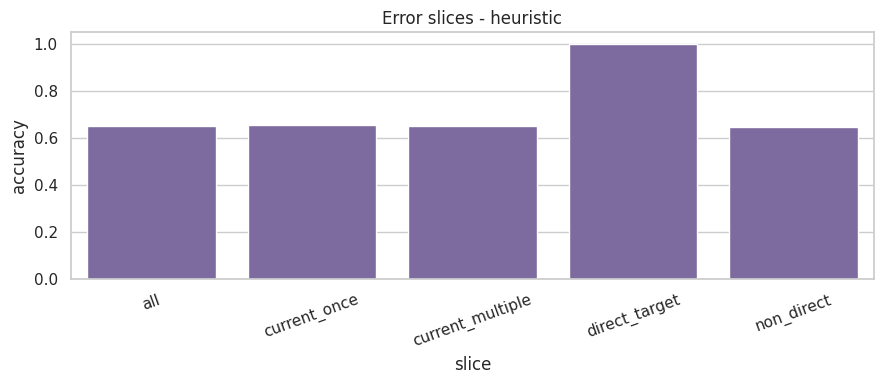

INSIGHT ERROR: bandingkan current_once vs current_multiple untuk mengukur ketergantungan pada click prior; direct-target slice kecil sehingga tidak boleh mendominasi keputusan model.


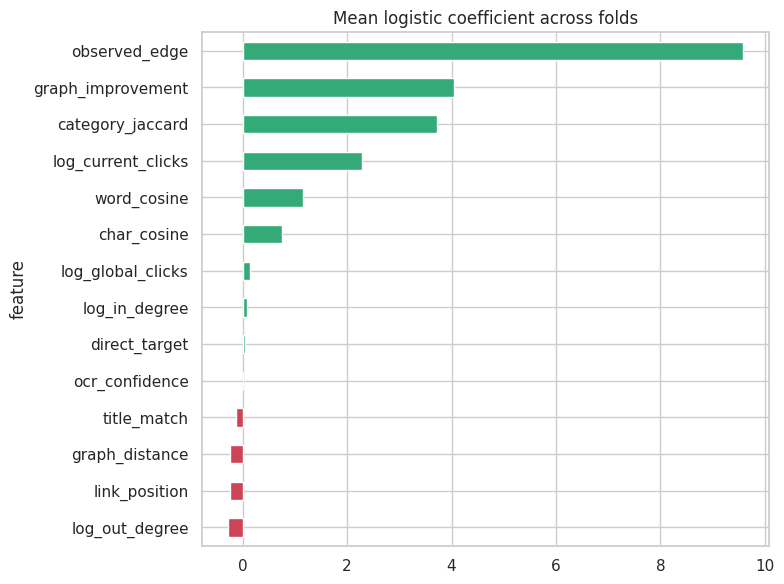

,state_id,current_article_id,target_article_id,predicted_title,true_title
0,2,3483,1013,Pacific Ocean,United Nations
1,23,1637,3122,Africa,United States
2,30,738,2396,United Kingdom,Islam
3,52,3370,1225,Ulysses S. Grant,President of the United States
4,67,3557,2285,Europe,United States
5,77,3182,3946,19th century,United Kingdom
6,82,3838,3946,20th century,Spain
7,101,1111,3360,Water Buffalo,16th century
8,121,547,2789,United States,China
9,123,3509,474,AIDS,Zambia


In [17]:
eligible_models = ['heuristic','logistic','hist_gbdt','rank_ensemble','current_ranker_fallback']
BEST_MODEL = cv_summary.mean_accuracy.idxmax()
BEST_PAIR_MODEL = cv_summary.loc[[m for m in eligible_models if m in cv_summary.index]].mean_accuracy.idxmax()
winner_df = pd.concat(oof_winners,ignore_index=True)
best_oof = winner_df[winner_df.model==BEST_PAIR_MODEL].merge(train[['state_id','current_article_id','target_article_id','next_article_id']],on='state_id',how='left')
best_oof['correct'] = best_oof.candidate_id == best_oof.next_article_id
best_oof['current_frequency'] = best_oof.current_article_id.map(train.current_article_id.value_counts())
best_oof['direct_target'] = best_oof.next_article_id == best_oof.target_article_id
error_slices = pd.DataFrame({
    'slice':['all','current_once','current_multiple','direct_target','non_direct'],
    'states':[len(best_oof),(best_oof.current_frequency==1).sum(),(best_oof.current_frequency>1).sum(),best_oof.direct_target.sum(),(~best_oof.direct_target).sum()],
    'accuracy':[best_oof.correct.mean(),best_oof.loc[best_oof.current_frequency==1,'correct'].mean(),best_oof.loc[best_oof.current_frequency>1,'correct'].mean(),best_oof.loc[best_oof.direct_target,'correct'].mean(),best_oof.loc[~best_oof.direct_target,'correct'].mean()]
})
display(error_slices); print('Selected overall model:', BEST_MODEL, '| best pair ranker:', BEST_PAIR_MODEL)
fig,ax=plt.subplots(figsize=(9,4)); sns.barplot(data=error_slices,x='slice',y='accuracy',ax=ax,color='#7b61a8'); ax.set_title(f'Error slices - {BEST_PAIR_MODEL}'); ax.tick_params(axis='x',rotation=20); plt.tight_layout(); plt.show()
print('INSIGHT ERROR: bandingkan current_once vs current_multiple untuk mengukur ketergantungan pada click prior; direct-target slice kecil sehingga tidak boleh mendominasi keputusan model.')

coef_rows=[]
for fold,(logit,_) in enumerate(fold_models):
    coef_rows += [{'fold':fold,'feature':name,'coefficient':coef} for name,coef in zip(FEATURE_NAMES,logit.coef_[0])]
coef_df=pd.DataFrame(coef_rows); coef_summary=coef_df.groupby('feature').coefficient.mean().sort_values()
coef_summary.plot.barh(figsize=(8,6),color=np.where(coef_summary>0,'#33aa77','#cc4455')); plt.title('Mean logistic coefficient across folds'); plt.tight_layout(); plt.show()

wrong = best_oof[~best_oof.correct].merge(articles.rename(columns={'article_id':'candidate_id','title':'predicted_title'}),on='candidate_id',how='left')
wrong = wrong.merge(articles.rename(columns={'article_id':'next_article_id','title':'true_title'}),on='next_article_id',how='left')
display(wrong[['state_id','current_article_id','target_article_id','predicted_title','true_title']].head(20))


## 17. Final refit pada seluruh train dan prediksi test

Model terpilih di-refit menggunakan seluruh train. Candidate test menggabungkan OCR links dan seluruh observed transitions. Untuk model ensemble, komponen logistic dan gradient boosting sama-sama di-refit.


In [18]:
full_priors = fit_priors(train)
X_full, y_full, meta_full = build_pairs(train, full_priors, True, MAX_TRAIN_CANDIDATES)
X_test, _, meta_test = build_pairs(test, full_priors, False, MAX_EVAL_CANDIDATES)
pos_weight = max((len(y_full)-y_full.sum())/max(y_full.sum(),1),1)
full_weight = np.where(y_full==1,pos_weight,1.0)

final_logit = LogisticRegression(C=1.0,max_iter=300,solver='liblinear',random_state=SEED).fit(X_full,y_full,sample_weight=full_weight)
final_hgb = HistGradientBoostingClassifier(max_iter=140 if not FAST_MODE else 35,learning_rate=.07,max_leaf_nodes=31,min_samples_leaf=25,l2_regularization=2.0,random_state=SEED).fit(X_full,y_full,sample_weight=full_weight)
import joblib
MODEL_PATH = OUTPUT_DIR/'datathon_task2_v1_rankers.joblib'
joblib.dump({'logistic':final_logit,'hist_gbdt':final_hgb,'features':FEATURE_NAMES,'selected_model':BEST_MODEL}, MODEL_PATH)
test_scores = {
    'heuristic': heuristic_score(X_test),
    'logistic': final_logit.predict_proba(X_test)[:,1],
    'hist_gbdt': final_hgb.predict_proba(X_test)[:,1],
}
test_scores['rank_ensemble'] = .15*rank_normalize(meta_test,test_scores['heuristic']) + .25*rank_normalize(meta_test,test_scores['logistic']) + .60*rank_normalize(meta_test,test_scores['hist_gbdt'])
full_current_counts = full_priors[1]
full_mode_by_current = {int(c):counter.most_common(1)[0][0] for c,counter in full_current_counts.items() if counter}
test_mode_boost = np.asarray([10.0 if full_mode_by_current.get(int(c))==int(k) else 0.0 for c,k in zip(meta_test.current,meta_test.candidate_id)],dtype=np.float32)
test_scores['current_ranker_fallback'] = test_scores['rank_ensemble'] + test_mode_boost
if BEST_MODEL == 'global_mode':
    test_prediction = pd.Series(full_priors[3][0],index=test.state_id,dtype=int)
elif BEST_MODEL == 'current_mode':
    global_mode = full_priors[3][0]
    test_prediction = pd.Series([full_mode_by_current.get(int(c),global_mode) for c in test.current_article_id],index=test.state_id,dtype=int)
else:
    selected_score = test_scores[BEST_MODEL]
    test_ranked = meta_test[['state_id','candidate_id','current','target']].copy(); test_ranked['score']=selected_score
    test_winners = test_ranked.sort_values(['state_id','score','candidate_id'],ascending=[True,False,True]).drop_duplicates('state_id')
    test_prediction = test_winners.set_index('state_id').candidate_id.astype(int)
print('Final model:',BEST_MODEL,'| train pairs:',len(X_full),'| test pairs:',len(X_test),'| predictions:',len(test_prediction)); stage('final refit')


Pair features:   0%|          | 0/9000 [00:00<?, ?it/s]

Pair features:   0%|          | 0/6000 [00:00<?, ?it/s]

Final model: heuristic | train pairs: 170047 | test pairs: 121270 | predictions: 6000
[runtime] final refit: 47.53 min cumulative


## 18. Submission creation dan strict audit

Submission selalu mengikuti urutan `sample_submission.csv`. Cell ini memeriksa row count, uniqueness, NaN, valid article IDs, dan seberapa sering prediction berasal dari candidate OCR/observed transition.


In [19]:
submission = sample_submission[['state_id']].copy()
submission['predicted_next_article_id'] = submission.state_id.map(test_prediction)
assert len(submission)==len(test) and submission.state_id.is_unique
assert submission.predicted_next_article_id.notna().all()
submission.predicted_next_article_id = submission.predicted_next_article_id.astype(int)
assert submission.predicted_next_article_id.isin(article_ids).all()
assert submission.state_id.tolist()==test.state_id.tolist()

test_lookup = test.set_index('state_id')
candidate_valid=[]
for r in submission.itertuples(index=False):
    current=int(test_lookup.loc[r.state_id,'current_article_id']); pred=int(r.predicted_next_article_id)
    candidate_valid.append(pred in ocr_candidates.get(current,set()) or pred in observed_full.get(current,set()))
audit = {
    'rows':len(submission),'unique_states':submission.state_id.nunique(),'unique_predictions':submission.predicted_next_article_id.nunique(),
    'nan':int(submission.isna().sum().sum()),'candidate_valid_rate':float(np.mean(candidate_valid)),
    'prediction_equals_current_rate':float(np.mean(submission.predicted_next_article_id.to_numpy()==test.current_article_id.to_numpy())),
    'prediction_equals_target_rate':float(np.mean(submission.predicted_next_article_id.to_numpy()==test.target_article_id.to_numpy())),
}
SUBMISSION_PATH=OUTPUT_DIR/'datathon_task2_v1_ocr_graph_ranker.csv'
submission.to_csv(SUBMISSION_PATH,index=False)
display(pd.Series(audit).to_frame('value')); display(pd.concat([submission.head(3),submission.tail(3)])); print('Saved:',SUBMISSION_PATH)


,value
rows,6000.000000
unique_states,6000.000000
unique_predictions,891.000000
nan,0.000000
candidate_valid_rate,1.000000
prediction_equals_current_rate,0.000000
prediction_equals_target_rate,0.007333


,state_id,predicted_next_article_id
0,0,4393
1,6,315
2,8,237
5997,14990,2994
5998,14993,1957
5999,14997,1752


Saved: /kaggle/working/datathon_task2_v1_ocr_graph_ranker.csv


## 19. Diagnostics export dan experiment summary

Seluruh konfigurasi, EDA penting, CV result, OCR coverage, model selection, runtime, dan submission audit disimpan agar run Kaggle dapat dianalisis tanpa mengandalkan output cell saja.


In [20]:
def json_safe(value):
    if isinstance(value,(np.integer,)): return int(value)
    if isinstance(value,(np.floating,)): return None if not np.isfinite(value) else float(value)
    if isinstance(value,np.ndarray): return value.tolist()
    if isinstance(value,dict): return {str(k):json_safe(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)): return [json_safe(v) for v in value]
    return value

diagnostics = {
    'version':'v1_ocr_graph_ranker','seed':SEED,'fast_mode':FAST_MODE,'dataset_path':str(DATASET_PATH),
    'integrity':integrity,'state_eda':state_eda.to_dict(),'graph_eda':graph_eda.value.to_dict(),
    'cv_summary':cv_summary.reset_index().to_dict('records'),'selected_model':BEST_MODEL,
    'feature_names':FEATURE_NAMES,'submission_audit':audit,'runtime_minutes':elapsed_minutes(),
    'ocr_available':OCR_AVAILABLE,'processed_ocr_pages':len(processed_ids),'extracted_edges':len(links),
}
DIAGNOSTICS_PATH=OUTPUT_DIR/'datathon_task2_v1_diagnostics.json'
DIAGNOSTICS_PATH.write_text(json.dumps(json_safe(diagnostics),indent=2))
REUSABLE_LINKS = REUSABLE_DIR/'task2_v1_link_candidates.csv'
REUSABLE_RAW = REUSABLE_DIR/'task2_v1_ocr_raw_regions.csv'
REUSABLE_PROCESSED = REUSABLE_DIR/'task2_v1_ocr_processed.json'
links.to_csv(REUSABLE_LINKS,index=False); raw_ocr.to_csv(REUSABLE_RAW,index=False); REUSABLE_PROCESSED.write_text(json.dumps(sorted(processed_ids)))
reusable_manifest = {
    'bundle_version':'task2_v1_reusable_v1','created_by':'datathon_task2_v1_eda_ocr_graph_ranker_source.ipynb',
    'processed_pages':len(processed_ids),'expected_pages':len(articles),'is_complete':len(processed_ids)==len(articles),
    'accepted_links':len(links),'raw_ocr_regions':len(raw_ocr),'raw_candidate_recall_train':float(raw_recall),
    'files':{'links':REUSABLE_LINKS.name,'raw_ocr':REUSABLE_RAW.name,'processed_pages':REUSABLE_PROCESSED.name,'quality_by_page':OCR_QUALITY_PATH.name,'manual_review_sample':OCR_REVIEW_SAMPLE_PATH.name,'review_images':OCR_REVIEW_DIR.name},
    'reuse_note':'Upload this directory/ZIP as a Kaggle Dataset, attach it to V2, then load task2_v1_link_candidates.csv as the precomputed hyperlink graph.'
}
(REUSABLE_DIR/'manifest.json').write_text(json.dumps(json_safe(reusable_manifest),indent=2))
(REUSABLE_DIR/'README_REUSE.txt').write_text('V2 REUSE: attach this bundle as a Kaggle Dataset/Input. Load task2_v1_link_candidates.csv for model candidates, inspect task2_v1_ocr_raw_regions.csv and ocr_review_images/ for quality, and check manifest.json is_complete before skipping OCR.\n')
BUNDLE_ZIP = Path(shutil.make_archive(str(OUTPUT_DIR/'datathon_task2_v1_reusable_bundle'),'zip',root_dir=REUSABLE_DIR))
print('Artifacts:'); print('-',SUBMISSION_PATH); print('-',DIAGNOSTICS_PATH); print('-',OUTPUT_DIR/'datathon_task2_v1_cv_results.csv'); print('-',MODEL_PATH); print('-',REUSABLE_DIR); print('-',BUNDLE_ZIP)
stage('all complete')


Artifacts:
- /kaggle/working/datathon_task2_v1_ocr_graph_ranker.csv
- /kaggle/working/datathon_task2_v1_diagnostics.json
- /kaggle/working/datathon_task2_v1_cv_results.csv
- /kaggle/working/datathon_task2_v1_rankers.joblib
- /kaggle/working/datathon_task2_v1_reusable
- /kaggle/working/datathon_task2_v1_reusable_bundle.zip
[runtime] all complete: 47.57 min cumulative


## 20. Kesimpulan dan handoff

Setelah run Kaggle selesai, unduh notebook executed dan seluruh artifact dari `/kaggle/working`. Catat di `codex.md`: runtime OCR, raw candidate recall, grouped CV per model, model terpilih, error slice, submission audit, leaderboard score jika sudah submit, keputusan, dan next experiment.

Untuk V2, simpan `datathon_task2_v1_reusable_bundle.zip` atau folder `datathon_task2_v1_reusable/` sebagai Kaggle Dataset. Setelah di-attach sebagai input V2, periksa `manifest.json` (`is_complete=true`), review box hijau/merah pada `ocr_review_images/`, lalu gunakan `task2_v1_link_candidates.csv` sebagai precomputed graph tanpa mengulang OCR.

Interpretasi utama V1:

- jika candidate recall rendah, prioritaskan perbaikan region grouping/OCR/title matching sebelum model baru;
- jika recall tinggi tetapi accuracy rendah, perbaiki semantic/graph ranking;
- jika current-mode menang, click prior kuat tetapi tetap audit unseen-current;
- GNN/large neural encoder hanya layak dicoba setelah graph coverage dan ranker baseline terukur.
